Loading images...
Training SVM model with RBF kernel... (This takes about 1-2 minutes)
New Model Accuracy: 55.00%


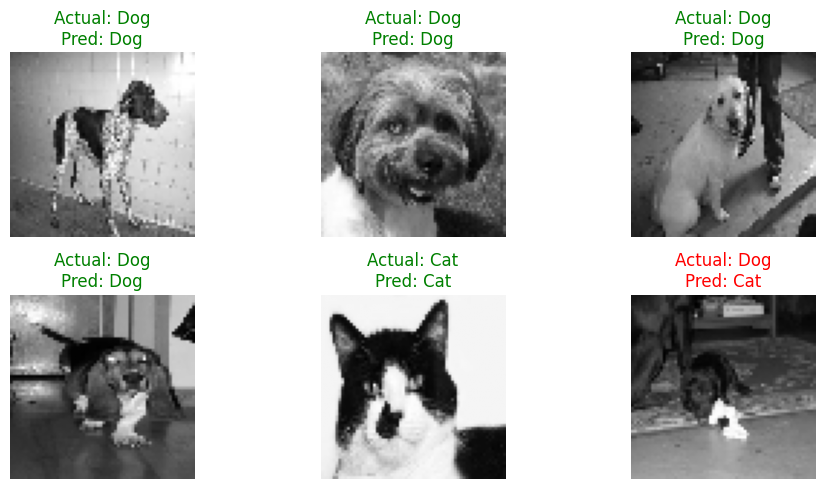

In [5]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import zipfile

# 1. Download and Extract (If you already downloaded, this will just skip quickly)
if not os.path.exists('kagglecatsanddogs_5340.zip'):
    print("Downloading dataset...")
    !wget -q https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip
    with zipfile.ZipFile('kagglecatsanddogs_5340.zip', 'r') as zip_ref:
        zip_ref.extractall('data')

data_dir = 'data/PetImages'

# 2. Load Images
def load_images(folder_path, label, limit=500):
    images = []
    labels = []
    count = 0
    for filename in os.listdir(folder_path):
        if count >= limit:
            break
        img_path = os.path.join(folder_path, filename)
        try:
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            img = cv2.resize(img, (64, 64))
            images.append(img.flatten())
            labels.append(label)
            count += 1
        except Exception:
            continue
    return images, labels

print("Loading images...")
cat_images, cat_labels = load_images(os.path.join(data_dir, 'Cat'), 0, 500)
dog_images, dog_labels = load_images(os.path.join(data_dir, 'Dog'), 1, 500)

X = np.array(cat_images + dog_images)
y = np.array(cat_labels + dog_labels)

# ---------------------------------------------------------
# 🚨 THE FIX: Normalize the data (Scale pixels from 0-255 to 0-1)
X = X / 255.0
# ---------------------------------------------------------

# 3. Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train the SVM model
print("Training SVM model with RBF kernel... (This takes about 1-2 minutes)")
# 🚨 THE FIX: Changed kernel from 'linear' to 'rbf'
svm_model = SVC(kernel='rbf')
svm_model.fit(X_train, y_train)

# 5. Test the model
y_pred = svm_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"New Model Accuracy: {accuracy * 100:.2f}%")

# 6. Visualize predictions
plt.figure(figsize=(10, 5))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(X_test[i].reshape(64, 64), cmap='gray')

    actual = "Cat" if y_test[i] == 0 else "Dog"
    predicted = "Cat" if y_pred[i] == 0 else "Dog"

    color = 'green' if actual == predicted else 'red'
    plt.title(f"Actual: {actual}\nPred: {predicted}", color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()